# Wetland Mapping with TropWet: Unmixing and Classification

*Section 13 — Case study: wetland mapping (TropWet), notebook 2 of 6.* Previous: `01_composite_and_endmembers`. Next: `03_change_and_accuracy`.

Notebook 01 built a median composite of the northern Rufiji delta and two endmember sets: the **TropWet** set, selected automatically with the published NDVI / MNDWI rules, whose "sand" endmember turned out to be wet mud, and a **bright sand** set, with the sand endmember replaced by the mean of the dry, low-NDVI pixels. This notebook unmixes the composite with both, and follows the steps of the [TropWet guide](https://rsgispy.readthedocs.io/en/latest/guides/spectral_unmixing.html) (unmixing, burn correction, classification), adding three things the guide only mentions:

1. a comparison of the three solvers (unconstrained, non-negative and fully constrained) on the same endmembers;
2. a per-pixel choice between the two endmember sets, by their error (a simple multiple endmember, MESMA, approach);
3. the sensitivity of the wetland areas to the 75 % / 25 % class limits.

**You will learn:**
- how to run and compare `spec_unmix_ucls`, `spec_unmix_nnls` and `spec_unmix_fcls`;
- how to calculate and map the unmixing error with `calc_unmixing_rmse_residual_err`, and summarise it per class;
- how to choose, per pixel, between endmember sets with `mesma` and a small spectral library;
- how to apply the TropWet burn correction and class rules with `band_maths`, and store the classes with `set_thematic_classes`;
- how to test the sensitivity of a rule-based classification to its thresholds.

**Before you start:** run `01_composite_and_endmembers`; this notebook reads its composite and endmembers.

**Data:** `outputs/inputs/sref_composite.tif` and `outputs/endmembers/*.csv` (from notebook 01). Outputs are written to `outputs/unmixing/`.

**Run time:** < 1 minute.

## Running Notebook

The notebook has been run and saved with the outputs so you can see what the outputs should be and so the notebook can be browsed online without having to run the notebook for it to make sense.

If you are running the notebook for yourself it is recommended that you clear the existing outputs which can be done by running one of the following options depending on what system you are using:

**Jupyter-lab**:

> \> _Edit_ \> _'Clear All Outputs'_

**Jupyter-notebook**:

> \> _Cell_ \> _'All Outputs'_ \> _Clear_

## 1. Import Modules

In [1]:
# Import the matplotlib plotting module and set it to work within
# a notebook environment.
%matplotlib inline

import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio

import rsgispy
import rsgispy.imagespectral.unmixing as unmix
from rsgispy.imagecalc.maths import BandDefn, band_maths
from rsgispy.imagecalc.stats import calc_basic_img_band_stats, count_pxls_of_val
import rsgispy.imagespectral.mesma as mesma
from rsgispy.imagespectral.endmembers import make_spectral_library, read_endmembers_df
from rsgispy.imageutils.bands import select_img_bands
from rsgispy.imageutils.colourtable import set_thematic_classes
from rsgispy.mapping.layout import MapPanel, create_map_panels

## 2. Define Input Data and Directories

In [2]:
in_dir = os.path.join("outputs", "inputs")
em_dir = os.path.join("outputs", "endmembers")
unmix_dir = os.path.join("outputs", "unmixing")
os.makedirs(unmix_dir, exist_ok=True)

refl_scale = 1000.0  # the images are reflectance x 1000
comp_img = os.path.join(in_dir, "sref_composite.tif")

em_files = {
    "tropwet": os.path.join(em_dir, "endmembers_tropwet.csv"),
    "bright": os.path.join(em_dir, "endmembers_bright_sand.csv"),
}
em_dfs = {name: read_endmembers_df(em_file) for name, em_file in em_files.items()}
em_dfs["tropwet"].round(0)

,Water,Vegetation,Sand
band,,,
Blue,58.0,25.0,63.0
Green,80.0,47.0,97.0
Red,64.0,34.0,104.0
NIR,32.0,317.0,146.0
SWIR1,12.0,123.0,103.0
SWIR2,11.0,55.0,66.0


## 3. Comparing the Solvers

The guide uses fully constrained least squares (FCLS). The three solvers in `rsgispy.imagespectral.unmixing` differ only in their constraints:

| Solver | Fractions ≥ 0 | Fractions sum to 1 |
| --- | --- | --- |
| `spec_unmix_ucls` (unconstrained) | no | no |
| `spec_unmix_nnls` (non-negative) | yes | no |
| `spec_unmix_fcls` (fully constrained) | yes | yes |

Each writes one band per endmember (the fraction, 0–1) and −9999 where a pixel was not unmixed (no data, or a band `<= 0`). `calc_unmixing_rmse_residual_err` compares the image with the reflectance modelled from the fractions: band 1 is the RMSE in image units (here reflectance x 1000), band 2 the RMSPE (%) and band 3 the mean absolute residual.

The function `summarise_unmixing` reads a fraction image and its error image, and returns the share of pixels with a negative fraction, the range of the sum of the fractions, the median and 99th percentile of the RMSE, and the median RMSPE.

In [3]:
def summarise_unmixing(frac_img, err_img):
    """Summary statistics of an unmixing result and its RMSE."""
    with rasterio.open(frac_img) as src:
        fracs = src.read().reshape(src.count, -1)
        vld = fracs[0] != src.nodata
    with rasterio.open(err_img) as src:
        rmse = src.read(1).ravel()[vld]
        rmspe = src.read(2).ravel()[vld]
    fracs = fracs[:, vld]
    return {
        "neg_pct": 100 * np.mean(np.any(fracs < 0, axis=0)),
        "sum_min": fracs.sum(axis=0).min(),
        "sum_max": fracs.sum(axis=0).max(),
        "rmse_median": np.median(rmse),
        "rmse_p99": np.percentile(rmse, 99),
        "rmspe_median": np.median(rmspe),
    }


solvers = {
    "ucls": unmix.spec_unmix_ucls,
    "nnls": unmix.spec_unmix_nnls,
    "fcls": unmix.spec_unmix_fcls,
}
solver_stats = {}
for solver_name, solver_fn in solvers.items():
    frac_img = os.path.join(unmix_dir, f"composite_tropwet_{solver_name}.tif")
    err_img = os.path.join(unmix_dir, f"composite_tropwet_{solver_name}_err.tif")
    solver_fn(comp_img, frac_img, em_dfs["tropwet"], use_pbar=False)
    unmix.calc_unmixing_rmse_residual_err(comp_img, frac_img, err_img, em_dfs["tropwet"],
                                          use_pbar=False)
    solver_stats[solver_name] = summarise_unmixing(frac_img, err_img)
pd.DataFrame(solver_stats).T.round(2)

,neg_pct,sum_min,sum_max,rmse_median,rmse_p99,rmspe_median
ucls,95.36,-0.95,1.92,6.25,34.66,16.85
nnls,0.00,0.40,4.30,13.12,85.11,24.68
fcls,0.00,1.00,1.00,18.24,129.91,28.90


- **UCLS** has the lowest error, because it has the most freedom, but almost every pixel has a negative fraction and the sums range far from one. A fraction of −40 % cannot be classified.
- **NNLS** removes the negative fractions, and the sums show how far the pixels are from the brightness of the endmember mixtures: sums above 1 are pixels brighter than any mixture (the bright, bare surfaces of notebook 01).
- **FCLS** forces the sum to one, so the fractions can be read as percentages and classified with the TropWet rules, at the cost of a higher error where the endmembers do not fit.

Compare errors between models with the **same** constraints: a lower UCLS error does not make its fractions better. The rest of this notebook uses FCLS, as the guide does.

## 4. Unmixing with the Bright Sand Endmembers

In [4]:
frac_imgs = {"tropwet": os.path.join(unmix_dir, "composite_tropwet_fcls.tif")}
err_imgs = {"tropwet": os.path.join(unmix_dir, "composite_tropwet_fcls_err.tif")}

frac_imgs["bright"] = os.path.join(unmix_dir, "composite_bright_fcls.tif")
err_imgs["bright"] = os.path.join(unmix_dir, "composite_bright_fcls_err.tif")
unmix.spec_unmix_fcls(comp_img, frac_imgs["bright"], em_dfs["bright"], use_pbar=False)
unmix.calc_unmixing_rmse_residual_err(comp_img, frac_imgs["bright"], err_imgs["bright"],
                                      em_dfs["bright"], use_pbar=False)

pd.DataFrame(
    {name: summarise_unmixing(frac_imgs[name], err_imgs[name]) for name in frac_imgs}
).T.round(2)

,neg_pct,sum_min,sum_max,rmse_median,rmse_p99,rmspe_median
tropwet,0.0,1.0,1.0,18.24,129.91,28.90
bright,0.0,1.0,1.0,13.18,43.14,20.38


The median RMSE falls by a quarter and, above all, the 99th percentile falls by two thirds: the pixels that fitted worst are fitted much better. The maps show where. The colour scale is the same for both (0 to 60, i.e. 0–0.06 reflectance):

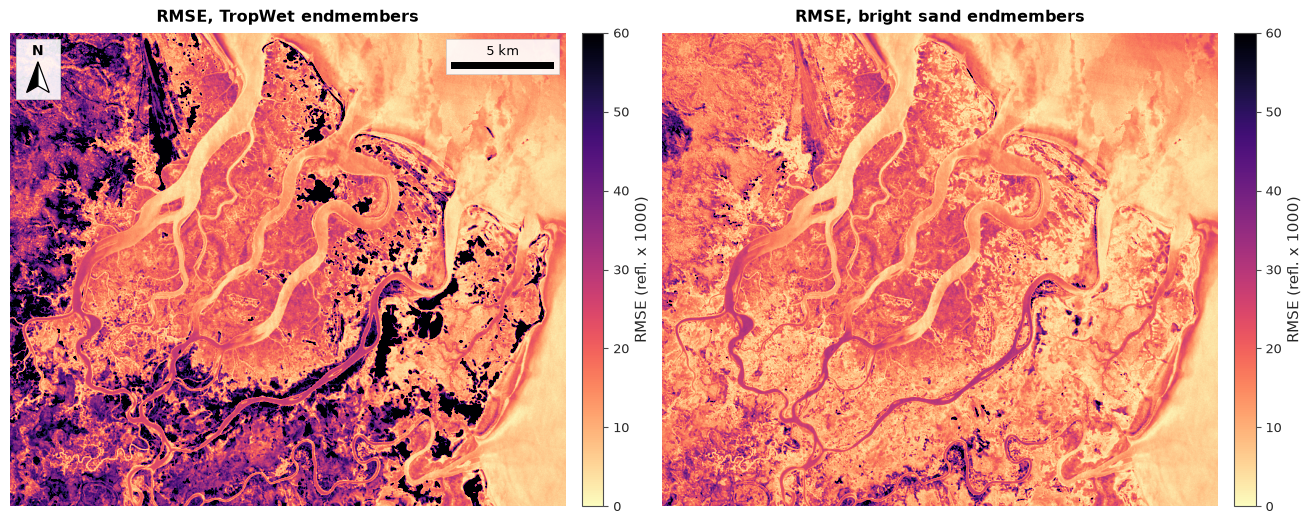

In [5]:
fig, axs = create_map_panels(
    [
        MapPanel("cmap", err_imgs["tropwet"], bands=1, title="RMSE, TropWet endmembers",
                 cmap_name="magma_r", vmin=0, vmax=60, show_colour_bar=True,
                 cbar_label="RMSE (refl. x 1000)"),
        MapPanel("cmap", err_imgs["bright"], bands=1, title="RMSE, bright sand endmembers",
                 cmap_name="magma_r", vmin=0, vmax=60, show_colour_bar=True,
                 cbar_label="RMSE (refl. x 1000)"),
    ],
    figsize=(13, 5.5),
)

With the TropWet endmembers the errors are highest on the bare and sparsely vegetated patches between the mangroves and on the farmland inland: the surfaces brighter than the wet mud endmember. The bright sand endmember fits them, but the error rises a little along the channels and their banks, where the wet mud endmember was a better description.

## 5. Fractions as Percentages and the TropWet Classes

### 5.1 Helper functions

Two functions are used for every unmixing result from here on (and again in notebook 03):

- `fracs_to_pct` converts the FCLS fractions to percentages (W, V and S), with no data −999;
- `classify_tropwet` applies the class rules of Hardy et al. (2020, Table 3), tested in order, with the upper (`hi`, default 75 %) and lower (`lo`, default 25 %) limits as arguments, so they can be changed in section 9. Wetland classes (1–3) are Open Water, Emergent Flooded Vegetation and Wet Bare Sand.

The data has no DEM of the delta, so the slope mask of the guide (Step 6) is left out: the delta is flat. With your own data, add it as the guide shows.

In [6]:
TROPWET_CLASSES = {
    1: ("Open Water (OW)", "#08519C"),
    2: ("Emergent Flooded Vegetation (EFV)", "#3FB8AF"),
    3: ("Wet Bare Sand (WBS)", "#B39C4D"),
    4: ("Dense Vegetation (GV)", "#1B7837"),
    5: ("Dry Sparse Vegetation (DSV)", "#A6D96A"),
    6: ("Dry Bare Sand (DBS)", "#F4E2B8"),
    7: ("Mixed / Other", "#BDBDBD"),
}
cls_names = {val: name for val, (name, _) in TROPWET_CLASSES.items()}


def fracs_to_pct(frac_img, pct_img):
    """FCLS fractions (no data -9999) to percentages (no data -999)."""
    band_maths(
        pct_img,
        ", ".join(f"{name} == -9999 ? -999 : 100 * {name}" for name in "WVS"),
        [BandDefn(name, frac_img, idx) for idx, name in enumerate("WVS", start=1)],
        band_names=["Water", "Vegetation", "Sand"],
        no_data_val=-999,
        use_pbar=False,
    )
    return pct_img


def classify_tropwet(pct_img, cls_img, hi=75, lo=25):
    """TropWet class rules (Hardy et al., 2020, Table 3) on W, V, S in %."""
    rules = [
        (1, f"W >= {hi}"),
        (2, f"W + V >= {hi} && V >= {lo} && V < {hi} && W >= {lo} && W < {hi}"),
        (3, f"W + S >= {hi} && W >= {lo} && W < {hi} && S >= {lo} && S < {hi}"),
        (4, f"V >= {hi}"),
        (5, f"V + S >= {hi} && V >= {lo} && V < {hi} && S >= {lo} && S < {hi}"),
        (6, f"S >= {hi}"),
    ]
    exp = "W < 0 ? 0 : "  # no data
    for code, rule in rules:
        exp += f"(({rule}) ? {code} : "
    exp += "7" + ")" * len(rules)  # anything else: Mixed / Other
    band_maths(
        cls_img,
        exp,
        [BandDefn(name, pct_img, idx) for idx, name in enumerate("WVS", start=1)],
        datatype=rsgispy.TYPE_8UINT,
        band_names=["tropwet_class"],
        no_data_val=0,
        use_pbar=False,
    )
    set_thematic_classes(cls_img, TROPWET_CLASSES)
    return cls_img


def class_areas_ha(cls_img):
    """Area (ha) of each TropWet class."""
    with rasterio.open(cls_img) as src:
        pxl_ha = abs(src.res[0] * src.res[1]) / 10000.0
    counts = count_pxls_of_val(cls_img, list(TROPWET_CLASSES), img_band=1, use_pbar=False)
    return pd.Series(counts * pxl_ha, index=pd.Index(cls_names.values(), name="class"))

### 5.2 Classify both unmixing results

In [7]:
pct_imgs, cls_imgs = {}, {}
for name, frac_img in frac_imgs.items():
    pct_imgs[name] = fracs_to_pct(frac_img, os.path.join(unmix_dir, f"composite_{name}_pct.tif"))
    cls_imgs[name] = classify_tropwet(
        pct_imgs[name], os.path.join(unmix_dir, f"composite_{name}_classes.tif")
    )

pd.DataFrame({name: class_areas_ha(cls_img) for name, cls_img in cls_imgs.items()}).round(0)

,tropwet,bright
class,,
Open Water (OW),15611.0,16755.0
Emergent Flooded Vegetation (EFV),2609.0,3654.0
Wet Bare Sand (WBS),1399.0,205.0
Dense Vegetation (GV),33341.0,28446.0
Dry Sparse Vegetation (DSV),8113.0,8901.0
Dry Bare Sand (DBS),475.0,1155.0
Mixed / Other,581.0,3011.0


### 5.3 Error per class

The median RMSE of each endmember set, in the pixels of each class of the TropWet-endmember classification, shows which surfaces each set fits:

In [8]:
with rasterio.open(cls_imgs["tropwet"]) as src:
    cls_arr = src.read(1)
rmse_arrs = {}
for name, err_img in err_imgs.items():
    with rasterio.open(err_img) as src:
        rmse_arrs[name] = src.read(1)

pd.DataFrame(
    {
        name: {cls_names[val]: np.median(rmse[cls_arr == val]) for val in cls_names}
        for name, rmse in rmse_arrs.items()
    }
).round(1)

,tropwet,bright
Open Water (OW),8.100000,8.100000
Emergent Flooded Vegetation (EFV),11.900000,11.900000
Wet Bare Sand (WBS),18.700001,22.200001
Dense Vegetation (GV),22.200001,16.799999
Dry Sparse Vegetation (DSV),44.900002,11.000000
Dry Bare Sand (DBS),28.900000,13.700000
Mixed / Other,9.100000,9.100000


The bright sand endmember cuts the error of Dry Sparse Vegetation, the second largest land class, by three quarters, and also lowers the error of Dense Vegetation and Dry Bare Sand. Open water and the flooded vegetation are unchanged (they hardly contain any sand), and the error of Wet Bare Sand rises: the wet mud endmember fitted the mud banks better.

The class areas change too (section 5.2), and not only for the dry classes:

- **Wet Bare Sand almost disappears** (1,399 → 205 ha). The mud banks are much darker than the bright sand, so FCLS now describes them mostly as water with a little vegetation (Open Water or Emergent Flooded Vegetation) instead of water plus sand.
- **Dense Vegetation shrinks** by about 4,900 ha. The bright sand endmember has a fairly high NIR reflectance (0.24), so it can stand in for part of the vegetation of a less dense canopy, and the vegetation fraction of those pixels drops below 75 %. They become Emergent Flooded Vegetation, Dry Sparse Vegetation or Mixed / Other.

Both are reminders that the fractions are defined by the endmembers: "60 % sand" means "60 % of *this* sand spectrum".

## 6. Choosing the Endmember Set per Pixel (MESMA)

Each set fits some surfaces better than the other, so keep, for every pixel, the result of the set that fits it best. This is the idea of multiple endmember spectral mixture analysis (MESMA; Roberts et al., 1998), here with just two candidate models.

`mesma` (in `rsgispy.imagespectral.mesma`) does this with a **spectral library**: spectra grouped into classes. Here the library has one water spectrum, one vegetation spectrum and two sand spectra (the TropWet wet mud and the bright sand). With `levels=(3,)` every model has one spectrum from each of the three classes, so there are two models, the two endmember sets. Each pixel is unmixed with both (FCLS) and the model with the lowest RMSE is kept. The constraints MESMA normally applies (fraction range, maximum RMSE, residuals) are switched off here, so every pixel gets the better of the two sets. Notebook 05 uses a larger library and the constraints.

The output has the class fractions (water, vegetation, sand), the chosen model (1 = wet mud, 2 = bright sand: the order of the returned model table) and its RMSE. `gain` puts the image and the library in reflectance (0–1).

In [9]:
library = make_spectral_library(
    pd.DataFrame(
        {
            "water": em_dfs["tropwet"]["Water"],
            "vegetation": em_dfs["tropwet"]["Vegetation"],
            "wet_mud": em_dfs["tropwet"]["Sand"],
            "bright_sand": em_dfs["bright"]["Sand"],
        }
    ),
    ["Water", "Vegetation", "Sand", "Sand"],
)
mesma_img = os.path.join(unmix_dir, "composite_mesma.tif")
models = mesma.mesma(
    comp_img,
    mesma_img,
    library,
    levels=(3,),  # one spectrum from each class in every model
    gain=refl_scale,
    min_frac=None, max_frac=None, max_rmse=None, max_resid=None,  # no constraints
    use_pbar=False,
)
print(models.to_string(index=False))

# The fractions (bands 1-3) and the chosen model (band 4) as separate images.
mesma_frac_img = os.path.join(unmix_dir, "composite_mesma_fcls.tif")
select_img_bands(mesma_img, mesma_frac_img, [1, 2, 3], calc_stats=False, use_pbar=False)
mesma_ref_img = os.path.join(unmix_dir, "composite_mesma_model.tif")
band_maths(
    mesma_ref_img, "model == -9999 ? 0 : model", [BandDefn("model", mesma_img, 4)],
    datatype=rsgispy.TYPE_8UINT, no_data_val=0, use_pbar=False,
)
set_thematic_classes(
    mesma_ref_img, {1: ("TropWet (wet mud) sand", "#B39C4D"), 2: ("Bright sand", "#F4A582")}
)

# The RMSE (band 1) and RMSPE (band 2) of the chosen model, for each pixel.
mesma_err_img = os.path.join(unmix_dir, "composite_mesma_err.tif")
band_maths(
    mesma_err_img,
    "ref == 1 ? e1 : (ref == 2 ? e2 : -1), ref == 1 ? p1 : (ref == 2 ? p2 : -1)",
    [BandDefn("ref", mesma_ref_img, 1),
     BandDefn("e1", err_imgs["tropwet"], 1), BandDefn("p1", err_imgs["tropwet"], 2),
     BandDefn("e2", err_imgs["bright"], 1), BandDefn("p2", err_imgs["bright"], 2)],
    band_names=["RMSE", "RMSPE"],
    no_data_val=-1,
    use_pbar=False,
)

frac_imgs["mesma"] = mesma_frac_img
err_imgs["mesma"] = mesma_err_img
n_model = count_pxls_of_val(mesma_ref_img, [1, 2], img_band=1, use_pbar=False)
print(f"Pixels using the TropWet set: {n_model[0]}, the bright sand set: {n_model[1]}")

 model  level               classes                      spectra
     1      3 Water+Vegetation+Sand     water+vegetation+wet_mud
     2      3 Water+Vegetation+Sand water+vegetation+bright_sand


Pixels using the TropWet set: 359698, the bright sand set: 330602


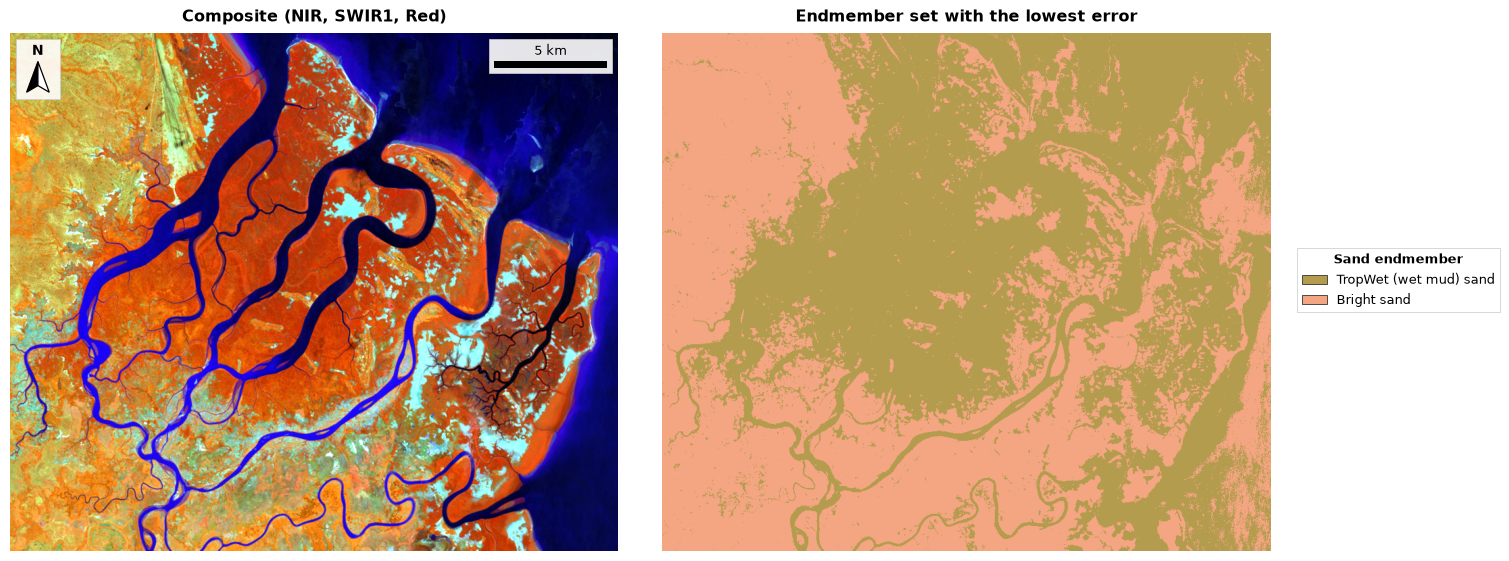

In [10]:
fig, axs = create_map_panels(
    [
        MapPanel("rgb", comp_img, bands=[4, 5, 3], title="Composite (NIR, SWIR1, Red)"),
        MapPanel("thematic", mesma_ref_img, title="Endmember set with the lowest error"),
    ],
    figsize=(13, 5.5),
    legend_title="Sand endmember",
)

The bright sand endmember is chosen for the farmland in the west and south and for the bare patches (salt flats) inside the mangroves, which are cyan in the composite. The wet mud endmember is chosen for most of the mangrove forest and along the channels. Over open water and dense forest the sand fraction is small, so the two fits are almost identical and the choice there means little: the sea is split between the two.

## 7. Burn Scar Correction

Freshly burned ground is dark in every band and unmixes as a mixture of water and sand. TropWet flags pixels with a high Burned Area Index (BAI > mean + 1 standard deviation), similar water and sand fractions (−0.5 < NDWS < 0.5, NDWS = (W − S) / (W + S)) and little vegetation (V < 10 %), and moves their water fraction to sand. The code is the same as in the guide (Step 5), applied to the MESMA fractions.

In [11]:
pct_imgs["mesma"] = fracs_to_pct(mesma_frac_img, os.path.join(unmix_dir, "composite_mesma_pct.tif"))

# Burned Area Index (Chuvieco et al., 2002) on reflectance 0-1; 0 = no data.
bai_img = os.path.join(unmix_dir, "composite_bai.tif")
band_maths(
    bai_img,
    f"red > 0 ? 1 / ((0.1 - red / {refl_scale})^2 + (0.06 - nir / {refl_scale})^2) : 0",
    [BandDefn("red", comp_img, 3), BandDefn("nir", comp_img, 4)],
    use_pbar=False,
)
_, _, bai_mean, bai_std = calc_basic_img_band_stats(bai_img, no_data_val=0, use_pbar=False)
bai_thres = float(bai_mean[0] + bai_std[0])
print(f"BAI threshold (mean + 1 sd): {bai_thres:.1f}")

pct_defs = [BandDefn(name, pct_imgs["mesma"], idx) for idx, name in enumerate("WVS", start=1)]
burn_img = os.path.join(unmix_dir, "composite_burn_flag.tif")
band_maths(
    burn_img,
    f"(W >= 0 && W + S > 0 && bai > {bai_thres} && abs((W - S) / (W + S)) < 0.5"
    " && V < 10) ? 1 : 0",
    pct_defs + [BandDefn("bai", bai_img, 1)],
    datatype=rsgispy.TYPE_8UINT,
    use_pbar=False,
)
corr_pct_img = os.path.join(unmix_dir, "composite_mesma_pct_burn_corr.tif")
band_maths(
    corr_pct_img,
    "burn ? 0 : W, V, burn ? S + W : S",
    pct_defs + [BandDefn("burn", burn_img, 1)],
    band_names=["Water", "Vegetation", "Sand"],
    no_data_val=-999,
    use_pbar=False,
)
n_burn = count_pxls_of_val(burn_img, [1], img_band=1, use_pbar=False)[0]
print(f"{n_burn} pixels corrected for burn scars")

BAI threshold (mean + 1 sd): 11823.8
148 pixels corrected for burn scars


As in the guide, the few flagged pixels are not burn scars but turbid water and mud at the edge of the channels, whose red and NIR reflectance is close to the "charcoal point" of the BAI. The correction is small here; in a savanna floodplain in the dry season it matters much more. Check the flag image (`composite_burn_flag.tif`) against a fire product before trusting it.

## 8. The Final Classification

In [12]:
cls_imgs["mesma"] = classify_tropwet(
    corr_pct_img, os.path.join(unmix_dir, "composite_mesma_classes.tif")
)
areas_df = pd.DataFrame({name: class_areas_ha(cls_img) for name, cls_img in cls_imgs.items()})
areas_df.columns = ["TropWet endmembers", "Bright sand", "MESMA + burn corr."]
areas_df.round(0)

,TropWet endmembers,Bright sand,MESMA + burn corr.
class,,,
Open Water (OW),15611.0,16755.0,15682.0
Emergent Flooded Vegetation (EFV),2609.0,3654.0,3109.0
Wet Bare Sand (WBS),1399.0,205.0,1479.0
Dense Vegetation (GV),33341.0,28446.0,28386.0
Dry Sparse Vegetation (DSV),8113.0,8901.0,9220.0
Dry Bare Sand (DBS),475.0,1155.0,1303.0
Mixed / Other,581.0,3011.0,2948.0


In [13]:
pd.DataFrame(
    {name: summarise_unmixing(frac_imgs[name], err_imgs[name]) for name in frac_imgs}
).T[["rmse_median", "rmse_p99", "rmspe_median"]].round(1)

,rmse_median,rmse_p99,rmspe_median
tropwet,18.2,129.9,28.9
bright,13.2,43.1,20.4
mesma,13.0,43.1,20.2


`mesma` keeps, per pixel, the model with the lowest **RMSE**, so the MESMA result has the lowest median RMSE of the three (13.0) and the same 99th percentile as the bright sand set: the worst-fitting pixels are the bright dry ground, where the bright sand model is chosen. Its median RMSPE (the error relative to the pixel's brightness) is close to that of the bright sand set; choosing by RMSPE instead would favour the wet mud model on dark pixels (water, mud), where a small absolute error is a large relative one.

The class areas of the MESMA result mostly sit between the two single-set results: the mud banks are Wet Bare Sand again (1,479 ha, close to the 1,399 ha of the TropWet set), described by the wet mud endmember, while the dry ground is described by the bright one.

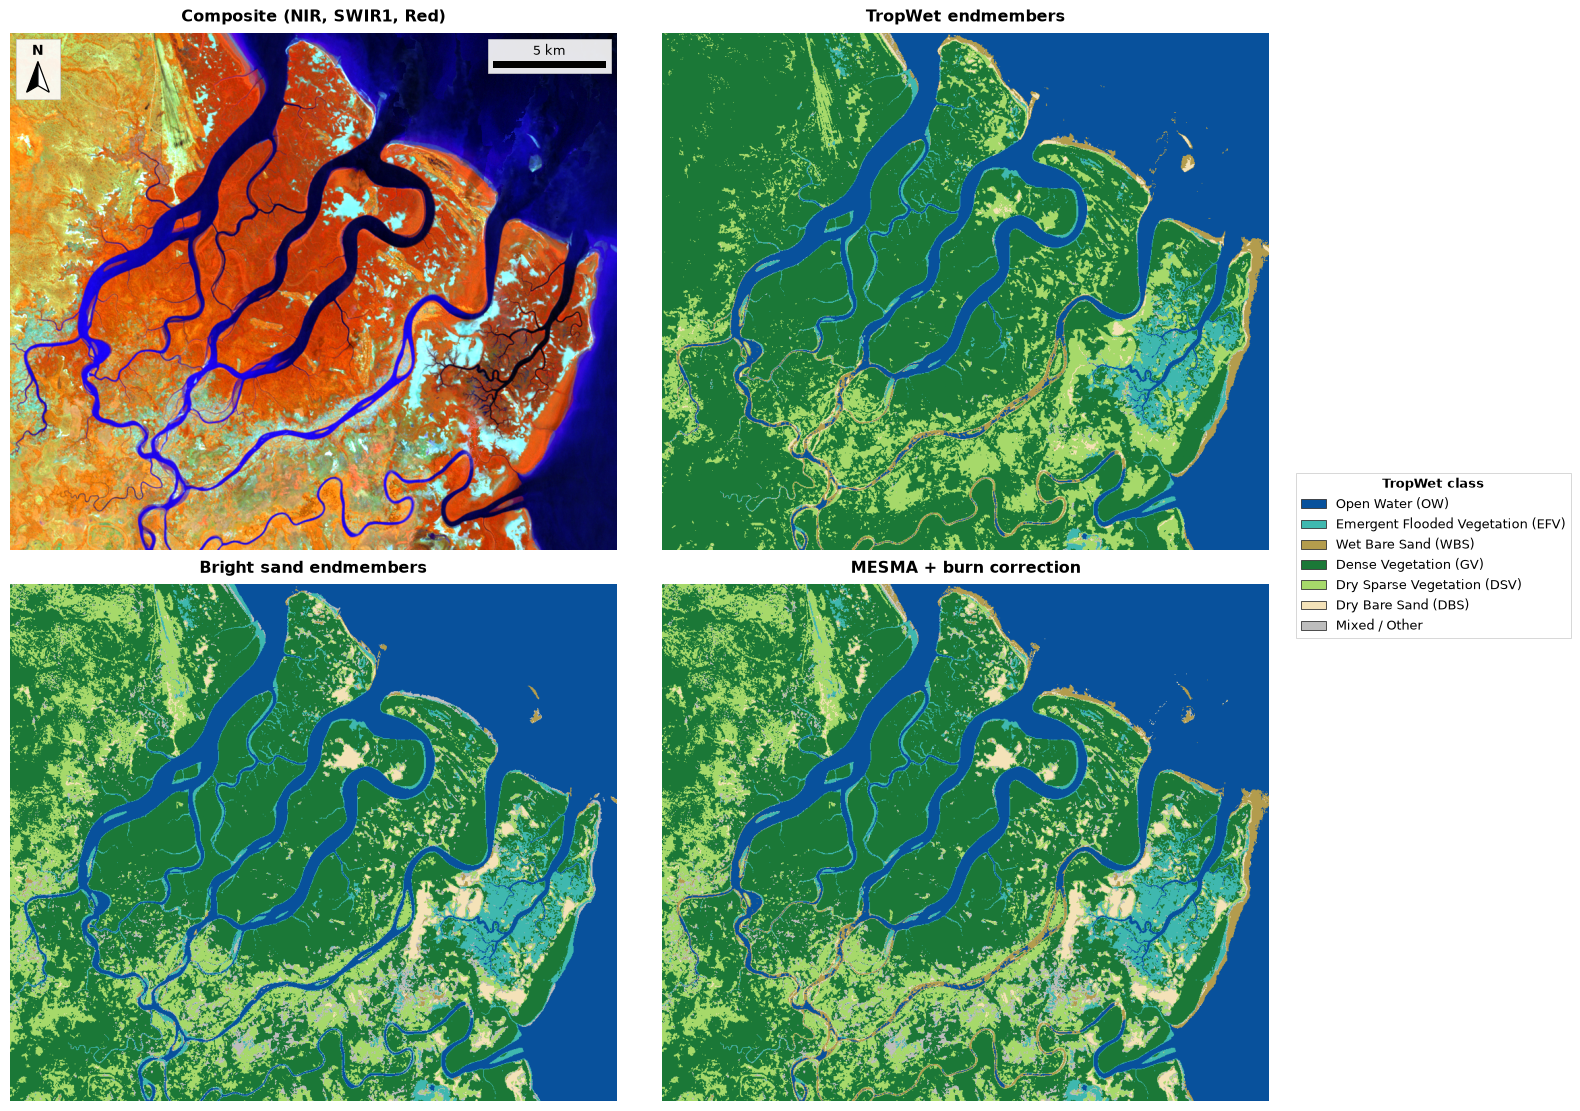

In [14]:
fig, axs = create_map_panels(
    [
        MapPanel("rgb", comp_img, bands=[4, 5, 3], title="Composite (NIR, SWIR1, Red)"),
        MapPanel("thematic", cls_imgs["tropwet"], title="TropWet endmembers"),
        MapPanel("thematic", cls_imgs["bright"], title="Bright sand endmembers"),
        MapPanel("thematic", cls_imgs["mesma"], title="MESMA + burn correction"),
    ],
    ncols=2,
    figsize=(13, 11),
    legend_title="TropWet class",
)

The fractions themselves are worth a look as an RGB image with a fixed 0–100 % stretch (sand red, vegetation green, water blue), so a colour always means the same mixture: cyan is flooded vegetation, purple wet sand and yellow-green dry, sparse vegetation.

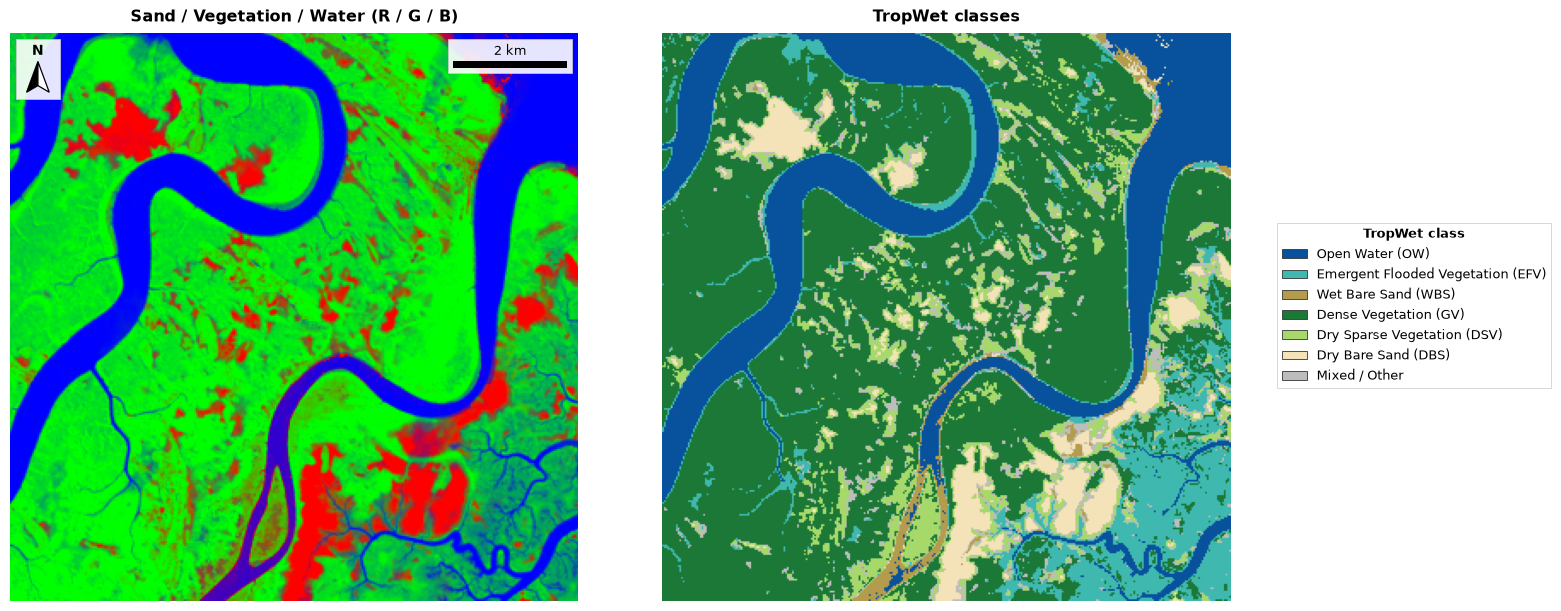

In [15]:
fig, axs = create_map_panels(
    [
        MapPanel("rgb", corr_pct_img, bands=[3, 2, 1], img_stch=rsgispy.IMG_STRETCH_USER,
                 title="Sand / Vegetation / Water (R / G / B)",
                 map_kw={"stch_min_max_vals": [{"min": 0.0, "max": 100.0}] * 3}),
        MapPanel("thematic", cls_imgs["mesma"], title="TropWet classes"),
    ],
    bbox=(536000, 546000, -870000, -860000),
    figsize=(13, 6),
    legend_title="TropWet class",
)

## 9. How Sensitive Are the Wetland Areas to the Class Limits?

The 75 % and 25 % class limits were derived in Barotseland, Zambia. Changing them shows how much the wetland areas depend on them. Here the upper limit `hi` is varied from 65 to 85 %, with the lower limit `lo = 100 − hi` (as in the original, where 25 = 100 − 75), and the MESMA fractions are classified again each time.

In [16]:
sens_dir = os.path.join(unmix_dir, "sensitivity")
os.makedirs(sens_dir, exist_ok=True)

sens_areas = {}
for hi in (65, 70, 75, 80, 85):
    sens_img = classify_tropwet(
        corr_pct_img, os.path.join(sens_dir, f"classes_hi{hi}.tif"), hi=hi, lo=100 - hi
    )
    sens_areas[hi] = class_areas_ha(sens_img)
sens_df = pd.DataFrame(sens_areas).T
sens_df.index.name = "hi (%)"
sens_df.round(0)

class,Open Water (OW),Emergent Flooded Vegetation (EFV),Wet Bare Sand (WBS),Dense Vegetation (GV),Dry Sparse Vegetation (DSV),Dry Bare Sand (DBS),Mixed / Other
hi (%),,,,,,,
65,16568.0,1375.0,531.0,34445.0,3768.0,1903.0,3537.0
70,16213.0,2140.0,940.0,31870.0,6210.0,1568.0,3186.0
75,15682.0,3109.0,1479.0,28386.0,9220.0,1303.0,2948.0
80,14927.0,4479.0,2186.0,23961.0,12353.0,1099.0,3123.0
85,14332.0,6745.0,2677.0,18835.0,14706.0,928.0,3905.0


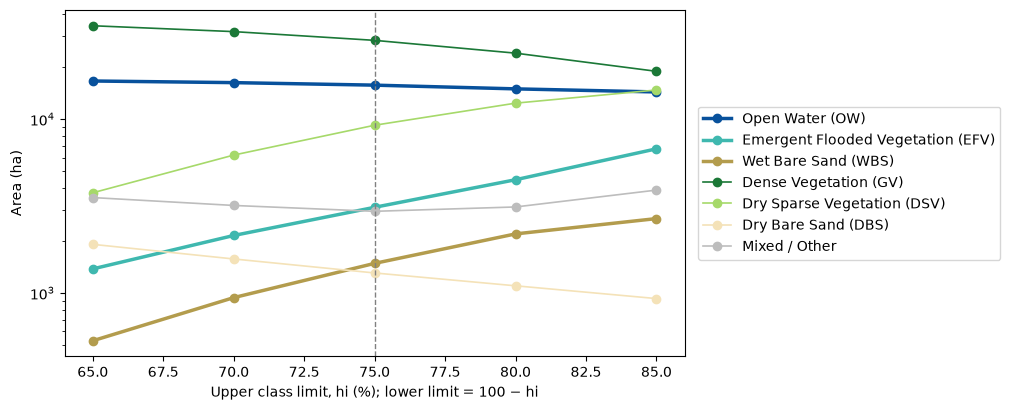

class,Open Water (OW),Emergent Flooded Vegetation (EFV),Wet Bare Sand (WBS)
hi (%),,,
65,6.0,-56.0,-64.0
70,3.0,-31.0,-36.0
75,0.0,0.0,0.0
80,-5.0,44.0,48.0
85,-9.0,117.0,81.0


In [17]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for val, (name, colour) in TROPWET_CLASSES.items():
    ax.plot(sens_df.index, sens_df[name], marker="o", color=colour, label=name,
            linewidth=2.5 if val <= 3 else 1.2)
ax.axvline(75, color="grey", ls="--", lw=1)
ax.set_xlabel("Upper class limit, hi (%); lower limit = 100 − hi")
ax.set_ylabel("Area (ha)")
ax.set_yscale("log")
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5))
plt.show()

wet_cls = [cls_names[val] for val in (1, 2, 3)]
(100 * sens_df[wet_cls].div(sens_df.loc[75, wet_cls]) - 100).round(0)

The last table is the change of each wetland class, in %, relative to the published limits. Open water is stable: its pixels are nearly pure water, far from any limit. The mixed wetland classes, Emergent Flooded Vegetation and Wet Bare Sand, are much more sensitive, because they are defined by a band of mixtures between two limits. Report them with this sensitivity in mind, and calibrate the limits with reference data from your own area if you can (notebook 03 shows a simple check against reference polygons).

## 10. Summary

- FCLS gives fractions that can be classified directly; the unconstrained solver has a lower error but fractions outside 0–1 for almost every pixel.
- The bright sand endmember fits the dry ground much better than the automatically selected wet mud endmember, and the wet mud endmember fits the mud banks better. Choosing per pixel (MESMA) keeps the strengths of both.
- Open water is robust to the choice of endmembers and limits; the mixed wetland classes are not.

Next, notebook `03_change_and_accuracy` classifies the 1997 and 2018 images on their own, maps the change between them and checks the classes against reference polygons.

**References**
- Chuvieco, E., Martín, M. P., Palacios, A. (2002). Assessment of different spectral indices in the red-near-infrared spectral domain for burned land discrimination. *International Journal of Remote Sensing*, 23(23), 5103–5110.
- Hardy, A., Oakes, G., Ettritch, G. (2020). Tropical Wetland (TropWet) Mapping Tool: The Automatic Detection of Open and Vegetated Waterbodies in Google Earth Engine for Tropical Wetlands. *Remote Sensing*, 12(7), 1182. https://doi.org/10.3390/rs12071182
- Roberts, D. A., Gardner, M., Church, R., Ustin, S., Scheer, G., Green, R. O. (1998). Mapping chaparral in the Santa Monica Mountains using multiple endmember spectral mixture models. *Remote Sensing of Environment*, 65(3), 267–279.